# 3. Measuring with instruments

`pemlab.instruments` takes the measurements: it controls the function generator, multimeter and
oscilloscope with pyvisa and writes CSV files that `lab.edit_csv(...)` reads (notebooks 1 and 2).

This notebook runs without hardware. A small **simulated** filter replaces the instruments; in the
lab you replace the marked lines with the real ones. Install with
`pip install "pemlab[instruments]"`.

## Find and open the instruments

`find_instruments()` lists everything that is connected, asks each device for `*IDN?` and prints the
code that opens it. Copy that block into your script:

```python
import pyvisa
from pemlab.instruments import AFG1022, Oscilloscope, find_instruments

find_instruments()                      # run once, then delete

rm = pyvisa.ResourceManager()
awg = AFG1022(rm.open_resource("USB0::0x0699::0x0353::1511374::INSTR"))
dmm = rm.open_resource("TCPIP::141.48.16.191::INSTR")
scope = Oscilloscope(rm.open_resource("TCPIP::..."))
```

| class / function | instrument |
|---|---|
| `AFG1022` | Tektronix AFG1022 function generator |
| `FunctionGenerator` | Rigol DG series |
| `Oscilloscope` | Rigol DS1000Z: `measure("vrms", ch)`, `read_waveform`, `screenshot` |
| `measure_voltage(dmm, ac=True)`, `measure_current`, `measure_resistance` | Rigol DM3000 multimeters |
| `PowerSupply` | Rigol DP800 |

## A simulated setup

`FakeResource` records the commands the generator receives. `u_out` simulates an RC high-pass with
$f_G = 700$ Hz and a little noise instead of reading the multimeters.

In [2]:
import numpy as np

from pemlab.instruments import AFG1022


class FakeResource:
    def __init__(self):
        self.written = []

    def write(self, command):
        self.written.append(command)


rng = np.random.default_rng(1)
awg = AFG1022(FakeResource())  # lab: AFG1022(rm.open_resource(address))
awg.settings("sine", frequency=1000, amplitude=1)
awg.resource.written

['OUTPut1:IMPedance 50',
 'SOURce1:FUNCtion:SHAPe SINusoid',
 'SOURce1:VOLTage:LEVel:IMMediate:OFFSet 0.0V',
 'SOURce1:VOLTage:LEVel:IMMediate:AMPLitude 1Vpp',
 'SOURce1:FREQuency:FIXed 1000Hz']

In [3]:
def u_in():                      # lab: measure_voltage(dmm_1, ac=True)
    return 0.354 * (1 + 0.002 * rng.standard_normal())


def u_out(f, f_g=700):           # lab: measure_voltage(dmm_2, ac=True)
    return 0.354 * (f / f_g) / np.sqrt(1 + (f / f_g) ** 2) * (1 + 0.004 * rng.standard_normal())

## A sweep inside a `with` block

`LogSweep(start, stop, n)` goes through the frequencies. **You write the loop yourself**: set the
instruments, wait, measure, and `sweep.add(...)` stores the row (the loop value first, then what
you pass). Other sweeps: `LinSweep` and `Timed` (measuring over time, endless without `duration`).

- the CSV is written **row by row**, nothing is lost if something goes wrong
- `sweep.wait(s)` waits and keeps live plots responsive
- **Ctrl+C** ends the measurement cleanly; the code behind the block still runs
- `LivePlot` shows the curve while measuring. `x` and `y` are a column name or a function of the
  row, so the live plot can show $|H| = U_a/U_e$ while the CSV keeps the raw voltages. It takes the
  same `PointStyle` and `LayoutStyle` as the final plots

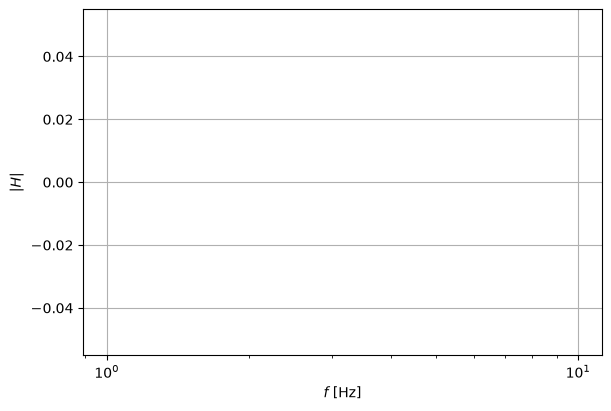

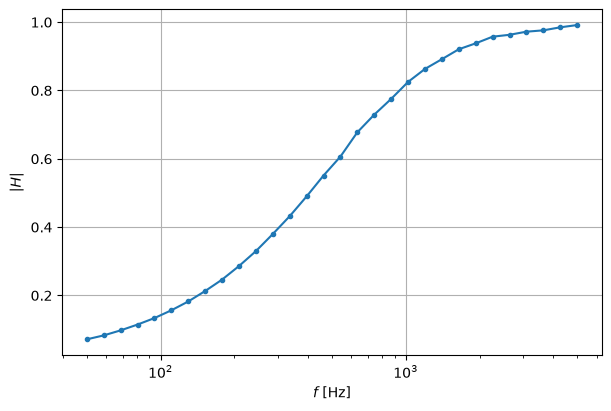

In [4]:
from pemlab import LayoutStyle
from pemlab.instruments import LivePlot, LogSweep

columns = ["f [Hz]", "U_e [V]", "U_a [V]"]

with LogSweep(50, 5000, 30, columns=columns, save="data/highpass.csv") as sweep:
    plot = LivePlot(
        sweep, x="f [Hz]", y=lambda r: r["U_a [V]"] / r["U_e [V]"],
        layout=LayoutStyle(xscale="log", ylabel="$|H|$", xlabel="$f$ [Hz]"),
    )
    for f in sweep:
        awg.set_frequency(f)
        sweep.wait(0.01)         # lab: 0.3 s or more
        sweep.add(u_in(), u_out(f))
plot.fig

`sweep.log` holds the rows, the CSV has them too:

In [5]:
sweep.log.to_dataframe().head(3)

,f [Hz],U_e [V],U_a [V]
0,50.000000,0.354245,0.025304
1,58.605115,0.354234,0.029380
2,68.691190,0.354641,0.034634


## Interrupting

In the lab you press Ctrl+C. Here we raise the same exception after 10 points:

In [6]:
with LogSweep(50, 5000, 30, columns=columns, save="data/interrupted.csv") as sweep:
    for k, f in enumerate(sweep):
        sweep.add(u_in(), u_out(f))
        if k == 9:
            raise KeyboardInterrupt

print(sweep.interrupted, len(sweep.log), "rows kept")

Messung abgebrochen nach 10 Zeilen.
True 10 rows kept


## Measuring over time

`Timed(interval, columns, duration)` stores the **real** time since the start as the first column.
Without `duration` it runs until Ctrl+C.

In [7]:
from pemlab.instruments import Timed

with Timed(0.05, columns=["t [s]", "U [V]"], duration=0.3) as run:
    for t in run:
        run.add(u_in())

run.log.to_dataframe()

,t [s],U [V]
0,0.000003,0.354549
1,0.050606,0.354137
2,0.100657,0.352845
3,0.150425,0.353154
4,0.200386,0.354626
5,0.250194,0.354481
6,0.300480,0.353547


## Evaluate

The CSV is an ordinary pemlab data file. Compute the gain from the raw voltages and fit:

f_g = 701.0 ± 1.4


FitResult(f_g=701)

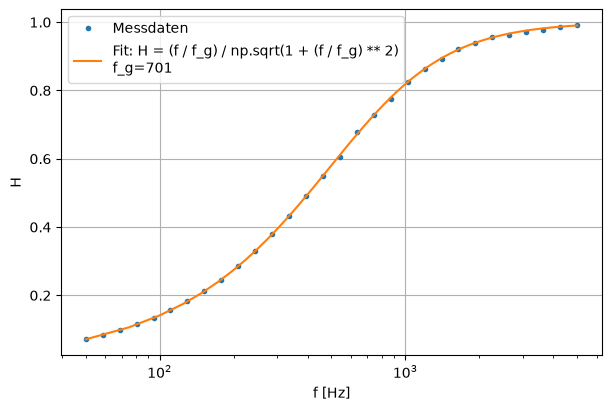

In [8]:
from pemlab import NumberStyle, Project

lab = Project("pemlab_build", tex_prefix="pemlab_build")
hp = lab.edit_csv("data/highpass.csv", name="highpass")
hp.add_column("H", "U_a / U_e", U_a="U_a [V]", U_e="U_e [V]",
              numbers=NumberStyle(decimals=3), show=True)


def highpass(x, f_g):
    return (x / f_g) / np.sqrt(1 + (x / f_g) ** 2)


analysis = lab.analysis(hp)
analysis.regression("highpass_gain", highpass, analysis.make_PlotData("f [Hz]", "H"), p0=[500],
                    layout=LayoutStyle(xscale="log"))